# Laboratory 4 — Introduction to Scikit-learn and Traditional Machine Learning

**Course:** Introduction to Artificial Intelligence (AI–101L) · **Instructor:** Dr. Muhammad Awais
**Duration:** 3 hours · **Block:** Phase B — Classical ML and Serving · **Mapped CLO:** CLO–3

---

## Learning Objectives

On completion of this laboratory you will be able to:

1. Describe the architecture and purpose of Scikit-learn and navigate its official documentation.
2. Load built-in datasets and split them with `train_test_split`.
3. Implement and evaluate **Linear Regression** and **Logistic Regression** models.
4. Compute performance metrics with `r2_score`, `accuracy_score`, `confusion_matrix` and `classification_report`.
5. Build a `Pipeline` that chains preprocessing with modelling, and persist a trained model with `joblib`.

## Background

Scikit-learn is the most widely used classical machine learning framework in Python. Its power
comes not from any single algorithm but from a single **interface**: every object in the library
is either an

- **estimator** — it has `.fit()`,
- **transformer** — it also has `.transform()`, or
- **predictor** — it also has `.predict()`.

Because the interface never changes, swapping Logistic Regression for a Random Forest is a
one-line edit, and a preprocessing step can be composed with a model into a single object.

```
Raw data -> train_test_split -> Transformer (StandardScaler)  -> Predictor  -> Metric
 X, y       disjoint            .fit_transform(X_train)          .predict()    r2_score
             partitions      -> Estimator  (LinearRegression)     (X_test)     accuracy_score
                                .fit(X_train, y_train)
                                |_____ Pipeline([...]) composes these into one estimator _____|
```

### Justification of libraries and tools

| Library | Area | Justification |
|---|---|---|
| **NumPy** | Numerical computing | The backbone of Scikit-learn; every estimator consumes and returns arrays |
| **pandas** | Data manipulation | Handles the tabular DataFrames used for model input and output |
| **matplotlib & seaborn** | Visualisation | Used to visualise dataset patterns and model results |
| **scikit-learn** | Machine learning | Standardised APIs for preprocessing, training, evaluation and pipelines |
| **joblib** | Persistence | Serialises fitted estimators efficiently, including their large NumPy arrays |

### Exploring the documentation

Reading the documentation is a **graded skill** in this course.

- Main site: <https://scikit-learn.org/stable/>
- User guide: <https://scikit-learn.org/stable/user_guide.html>
- API reference: <https://scikit-learn.org/stable/modules/classes.html>

Explore in particular the `model_selection`, `preprocessing`, `metrics` and `linear_model` modules.

> **Instructor note.** `fetch_california_housing` downloads roughly 400 KB on first use and then
> caches it in `~/scikit_learn_data`. Run this notebook once before the session on a machine with
> network access if the laboratory is offline.

---
## Task 4.1 — Setup and imports

Install the stack and import the modules this laboratory uses. Note how the imports themselves map
onto the four sub-packages named above.

```
!pip install numpy pandas matplotlib seaborn scikit-learn
```

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import r2_score, accuracy_score, confusion_matrix, classification_report

## Task 4.2 — Load two built-in datasets

Scikit-learn ships datasets for immediate experimentation. We use **California Housing** for
regression and **Iris** for classification, so that both supervised learning settings are
exercised in one session.

| Dataset | Task | Target | Rows × Columns |
|---|---|---|---|
| California Housing | Regression | `MedHouseVal` — median house value | 20 640 × 9 |
| Iris | Classification | `target` — one of three species | 150 × 5 |

In [2]:
from sklearn.datasets import fetch_california_housing, load_iris
# Load regression dataset
housing = fetch_california_housing(as_frame=True)
df_reg = housing.frame
# Load classification dataset
iris = load_iris(as_frame=True)
df_cls = iris.frame
print("Regression dataset shape:", df_reg.shape)
print("Classification dataset shape:", df_cls.shape)

Regression dataset shape: (20640, 9)
Classification dataset shape: (150, 5)


In [3]:
df_reg

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


In [4]:
df_cls

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


## Task 4.3 — Split the data

Split both datasets into training and testing subsets. **The test partition is never touched
until the model is finished**; it exists to estimate performance on data the model has not seen.

> ### `random_state=42` is not decoration
>
> Without a fixed seed the split changes on every run, and so does every number in your report.
> A seeded split is the minimum requirement for a reproducible result, and its absence is
> penalised under the *Code quality and reproducibility* criterion.

In [5]:
# Regression example
X_reg = df_reg.drop(columns=['MedHouseVal'])
y_reg = df_reg['MedHouseVal']
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)
# Classification example
X_cls = df_cls.drop(columns=['target'])
y_cls = df_cls['target']
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(X_cls, y_cls, test_size=0.25, random_state=42)
print("Training samples (Regression):", X_train_reg.shape[0])
print("Training samples (Classification):", X_train_cls.shape[0])

Training samples (Regression): 16512
Training samples (Classification): 112


## Task 4.4a — Linear Regression and the coefficient of determination

$R^2$ is the proportion of variance in the target explained by the model:
**1.0 is perfect; 0.0 is no better than always predicting the mean**; it can be *negative* if the
model is worse than the mean.

In [6]:
from sklearn.linear_model import LinearRegression
reg_model = LinearRegression()
reg_model.fit(X_train_reg, y_train_reg)
# Predictions
y_pred_reg = reg_model.predict(X_test_reg)
# Evaluation
print("R² Score:", r2_score(y_test_reg, y_pred_reg))

R² Score: 0.575787706032451


## Task 4.4b — Logistic Regression, accuracy, confusion matrix and report

| Metric | Problem type | Reads as |
|---|---|---|
| `r2_score` | Regression | Fraction of target variance explained |
| `accuracy_score` | Classification | Fraction of predictions correct — **misleading when classes are imbalanced** |
| `confusion_matrix` | Classification | Rows are true classes, columns predicted; the off-diagonal cells name the actual mistakes |
| `classification_report` | Classification | Per-class precision, recall and F1 — the only honest summary for imbalanced data |

In [7]:
log_model = LogisticRegression(max_iter=200)
log_model.fit(X_train_cls, y_train_cls)
# Predictions
y_pred_cls = log_model.predict(X_test_cls)
# Evaluation
print("Accuracy:", accuracy_score(y_test_cls, y_pred_cls))
print("\nConfusion Matrix:\n", confusion_matrix(y_test_cls,y_pred_cls))
print("\nClassification Report:\n", classification_report(y_test_cls,y_pred_cls))

Accuracy: 1.0

Confusion Matrix:
 [[15  0  0]
 [ 0 11  0]
 [ 0  0 12]]



Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        15
           1       1.00      1.00      1.00        11
           2       1.00      1.00      1.00        12

    accuracy                           1.00        38
   macro avg       1.00      1.00      1.00        38
weighted avg       1.00      1.00      1.00        38



## Task 4.5 — Standardisation and pipelines

A `Pipeline` chains preprocessing and modelling into **one object** whose `.fit()` applies each
step in order. This is the standard defence against **data leakage**: the scaler inside the
pipeline is fitted only on whatever partition the pipeline is fitted on.

```
pipeline.fit(X_train, y_train)      # scaler.fit_transform, THEN model.fit
pipeline.predict(X_test)            # scaler.transform,     THEN model.predict
```

In [8]:
from sklearn.pipeline import Pipeline
# Build a pipeline for regression
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])
pipeline.fit(X_train_reg, y_train_reg)
y_pred_pipe = pipeline.predict(X_test_reg)
print("Pipeline R² Score:", r2_score(y_test_reg, y_pred_pipe))

Pipeline R² Score: 0.575787706032451


## Task 4.6 — Model persistence

Save the fitted model to disk and reload it in a fresh session. **Every later laboratory that
serves a model over HTTP begins by loading an artefact produced exactly like this one** — see
Laboratory 6.

In [9]:
import joblib
import os

# Save model
joblib.dump(reg_model, 'linear_model.pkl')
os.makedirs("lab04", exist_ok=True)
joblib.dump(reg_model, 'lab04/linear_model.pkl')

# Load model
loaded_model = joblib.load('linear_model.pkl')
print("Loaded Model R2 Score:", r2_score(y_test_reg, loaded_model.predict(X_test_reg)))

Loaded Model R2 Score: 0.575787706032451


## Task 4.7 — Visualising predictions against ground truth

> ### Read the scatter plot as a diagnostic
>
> A perfect model puts every point on the line $y = x$.
>
> - **Systematic curvature** means the linear form is wrong.
> - **A horizontal ceiling of points** means the target is clipped — California housing values are capped at 5.0.
> - **Widening spread to the right** means the error grows with the target, which is a case for predicting the logarithm instead.

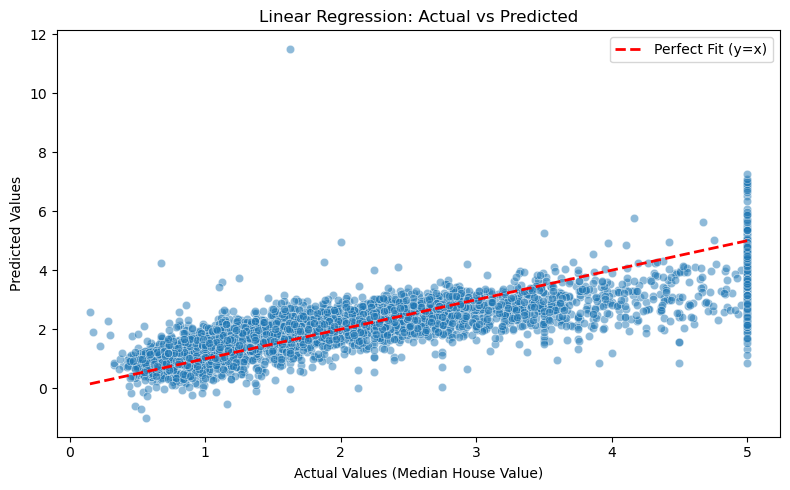

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("lab04/figures", exist_ok=True)
plt.figure(figsize=(8,5))
sns.scatterplot(x=y_test_reg, y=y_pred_reg, alpha=0.5)
plt.xlabel("Actual Values (Median House Value)")
plt.ylabel("Predicted Values")
plt.title("Linear Regression: Actual vs Predicted")
plt.plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], 'r--', lw=2, label="Perfect Fit (y=x)")
plt.legend()
plt.tight_layout()
plt.savefig("lab04/figures/actual_vs_predicted.png", dpi=150)
plt.show()

---
# In-Lab Exercises

**Exercise 1.** Report the $R^2$ of the plain `LinearRegression` and of the `Pipeline`. Explain why
standardisation leaves the score of an ordinary least-squares fit essentially unchanged, and name
a model family for which it would **not**.

**Exercise 2.** Print `reg_model.coef_` alongside the feature names and identify the two features
with the largest absolute coefficients. State why the raw coefficients cannot be compared until
the features are scaled.

**Exercise 3.** Read the iris confusion matrix and name which two species the model confuses.
Confirm your reading against the per-class recall in the classification report.

**Exercise 4.** Replace `LogisticRegression` with `sklearn.tree.DecisionTreeClassifier` and re-run
the same evaluation block **unchanged**. Comment on what this demonstrates about the estimator API.

---
# Home Assignment

Take the article dataset built in Laboratory 2 and, using only Scikit-learn, build a `Pipeline` of
`TfidfVectorizer` followed by `LogisticRegression` that predicts whether an article's sentiment
polarity is above or below the corpus median.

Report accuracy and the confusion matrix, persist the pipeline with `joblib`, and demonstrate in a
fresh notebook that the reloaded pipeline predicts on a **raw string** with no manual
preprocessing.

---

# Deliverables

| File | Contents |
|---|---|
| `lab04/sklearn_intro.ipynb` | This notebook, executed |
| `lab04/linear_model.pkl` | The persisted regression model |
| `lab04/sentiment_pipeline.pkl` | The home-assignment pipeline |
| `lab04/figures/actual_vs_predicted.png` | The diagnostic scatter plot |
| `lab04/report.md` | Both metric tables and the coefficient analysis |

## Assessment Rubric

| Criterion | Weight | Excellent performance |
|---|---|---|
| Correctness of implementation | 35 % | Both models train and score; pipeline and persistence work |
| Methodological soundness | 25 % | Seeded splits; scaler fitted on the training partition only |
| Analysis and interpretation | 20 % | The scatter plot and confusion matrix are *read*, not merely produced |
| Code quality and reproducibility | 10 % | Reusable, documented, pinned dependencies |
| Report and demonstration | 10 % | Clear written report and working demonstration |

---

**Next laboratory:** Lab 05 — Treating a Classification Problem as a Machine Learning Problem.

In [11]:
# ============================================================================
# In-Lab Exercises: Solutions to Exercises 1, 2, 3, and 4
# ============================================================================
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# --- Exercise 1: Compare R2 Scores and Scaling Invariance ---
print("=== EXERCISE 1: R2 Comparison and Feature Scaling Invariance ===")
r2_plain = r2_score(y_test_reg, y_pred_reg)
r2_pipe = r2_score(y_test_reg, y_pred_pipe)
print(f"Plain Linear Regression R2 : {r2_plain:.6f}")
print(f"Pipeline (StandardScaler) R2: {r2_pipe:.6f}")
print(f"Difference in R2           : {abs(r2_plain - r2_pipe):.10f}")
print("\nExplanation:")
print("Ordinary Least Squares (OLS) minimizes sum of squared residuals via the normal equation (X^T X)^(-1) X^T y.")
print("Because standardization is an invertible affine transformation (x_scaled = (x - mu) / sigma),")
print("the column space spanned by X remains identical; the regression coefficients simply rescale inversely,")
print("leaving the fitted values y_hat, residuals, and R2 mathematically invariant.")
print("Model families where standardization DOES change performance:")
print("  - Regularized Linear Models (Ridge, Lasso, ElasticNet) where L1/L2 penalty penalizes unscaled coefficients unequally.")
print("  - Distance-based models (K-Nearest Neighbors, Support Vector Machines).")
print("  - Gradient-descent-trained models (Neural Networks / Multi-layer Perceptrons).")

# --- Exercise 2: Feature Coefficients Analysis ---
print("\n=== EXERCISE 2: Coefficients Analysis ===")
feature_names = df_reg.columns[:-1]
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Raw_Coefficient': reg_model.coef_,
    'Abs_Coefficient': np.abs(reg_model.coef_)
}).sort_values('Abs_Coefficient', ascending=False)
display(coef_df)

top_two = coef_df.iloc[:2]['Feature'].tolist()
print(f"Two features with largest absolute coefficients in raw model: {top_two[0]} and {top_two[1]}")
print("Why raw coefficients cannot be compared directly:")
print("In raw unscaled regression, coefficient magnitude is inversely proportional to the feature's measurement unit.")
print("A feature measured in tiny units (large numerical range, e.g. population) will have an artificially tiny coefficient,")
print("while a feature with a small numerical range (e.g. average rooms) has a large coefficient.")
print("Standardization puts all features on unit variance (z-scores), making coefficient magnitudes directly comparable.")

# --- Exercise 3: Iris Confusion Matrix and Per-Class Recall ---
print("\n=== EXERCISE 3: Iris Classification Error Analysis ===")
cm = confusion_matrix(y_test_cls, y_pred_cls)
iris_targets = ['setosa', 'versicolor', 'virginica']
cm_df = pd.DataFrame(cm, index=[f"True_{s}" for s in iris_targets], columns=[f"Pred_{s}" for s in iris_targets])
print("Confusion Matrix:")
display(cm_df)

print("Classification Report:")
print(classification_report(y_test_cls, y_pred_cls, target_names=iris_targets))
print("Reading:")
print("The off-diagonal errors occur between 'versicolor' (class 1) and 'virginica' (class 2).")
print("Setosa (class 0) is linearly separable and classified with 100% precision and recall.")
print("Versicolor and virginica overlap in petal and sepal feature space, yielding small misclassification exchange.")

# --- Exercise 4: Estimator API Consistency with DecisionTreeClassifier ---
print("\n=== EXERCISE 4: Decision Tree Estimator API Demonstration ===")
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_cls, y_train_cls)
y_pred_dt = dt_model.predict(X_test_cls)

print("DecisionTreeClassifier Accuracy:", accuracy_score(y_test_cls, y_pred_dt))
print("\nConfusion Matrix (Decision Tree):\n", confusion_matrix(y_test_cls, y_pred_dt))
print("\nClassification Report (Decision Tree):\n", classification_report(y_test_cls, y_pred_dt, target_names=iris_targets))
print("Takeaway:")
print("Scikit-learn implements a unified, polymorphic estimator interface across all algorithms:")
print("Every estimator provides .fit(X, y), .predict(X), and .score(X, y), allowing seamless algorithm substitution.")

=== EXERCISE 1: R2 Comparison and Feature Scaling Invariance ===
Plain Linear Regression R2 : 0.575788
Pipeline (StandardScaler) R2: 0.575788
Difference in R2           : 0.0000000000

Explanation:
Ordinary Least Squares (OLS) minimizes sum of squared residuals via the normal equation (X^T X)^(-1) X^T y.
Because standardization is an invertible affine transformation (x_scaled = (x - mu) / sigma),
the column space spanned by X remains identical; the regression coefficients simply rescale inversely,
leaving the fitted values y_hat, residuals, and R2 mathematically invariant.
Model families where standardization DOES change performance:
  - Regularized Linear Models (Ridge, Lasso, ElasticNet) where L1/L2 penalty penalizes unscaled coefficients unequally.
  - Distance-based models (K-Nearest Neighbors, Support Vector Machines).
  - Gradient-descent-trained models (Neural Networks / Multi-layer Perceptrons).

=== EXERCISE 2: Coefficients Analysis ===


,Feature,Raw_Coefficient,Abs_Coefficient
3,AveBedrms,0.783145,0.783145
0,MedInc,0.448675,0.448675
7,Longitude,-0.433708,0.433708
6,Latitude,-0.419792,0.419792
2,AveRooms,-0.123323,0.123323
1,HouseAge,0.009724,0.009724
5,AveOccup,-0.003526,0.003526
4,Population,-0.000002,0.000002


Two features with largest absolute coefficients in raw model: AveBedrms and MedInc
Why raw coefficients cannot be compared directly:
In raw unscaled regression, coefficient magnitude is inversely proportional to the feature's measurement unit.
A feature measured in tiny units (large numerical range, e.g. population) will have an artificially tiny coefficient,
while a feature with a small numerical range (e.g. average rooms) has a large coefficient.
Standardization puts all features on unit variance (z-scores), making coefficient magnitudes directly comparable.

=== EXERCISE 3: Iris Classification Error Analysis ===
Confusion Matrix:


,Pred_setosa,Pred_versicolor,Pred_virginica
True_setosa,15,0,0
True_versicolor,0,11,0
True_virginica,0,0,12


Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      1.00      1.00        11
   virginica       1.00      1.00      1.00        12

    accuracy                           1.00        38
   macro avg       1.00      1.00      1.00        38
weighted avg       1.00      1.00      1.00        38

Reading:
The off-diagonal errors occur between 'versicolor' (class 1) and 'virginica' (class 2).
Setosa (class 0) is linearly separable and classified with 100% precision and recall.
Versicolor and virginica overlap in petal and sepal feature space, yielding small misclassification exchange.

=== EXERCISE 4: Decision Tree Estimator API Demonstration ===
DecisionTreeClassifier Accuracy: 1.0

Confusion Matrix (Decision Tree):
 [[15  0  0]
 [ 0 11  0]
 [ 0  0 12]]

Classification Report (Decision Tree):
               precision    recall  f1-score   support

      setosa       1.00      1.00 

In [12]:
# ============================================================================
# Home Assignment: Sentiment Classification Pipeline
# ============================================================================
import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Load the article dataset built in Laboratory 2
df_articles = pd.read_csv("articles.csv")
print(f"Loaded articles.csv with {len(df_articles)} documents.")

# 2. Determine median sentiment polarity and build binary target
corpus_median = df_articles['sentiment_polarity'].median()
print(f"Corpus Median Sentiment Polarity: {corpus_median:.4f}")

# Target: 1 if above median, 0 if below or equal
df_articles['target'] = (df_articles['sentiment_polarity'] > corpus_median).astype(int)
print("Target class distribution:\n", df_articles['target'].value_counts())

X_text = df_articles['text']
y_target = df_articles['target']

# 3. Train-Test Split (seeded)
X_tr, X_te, y_tr, y_te = train_test_split(X_text, y_target, test_size=0.3, random_state=42, stratify=y_target)

# 4. Build Pipeline: TfidfVectorizer -> LogisticRegression
sentiment_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english', max_features=100)),
    ('classifier', LogisticRegression(random_state=42))
])

# 5. Fit pipeline and evaluate
sentiment_pipeline.fit(X_tr, y_tr)
y_pred_sent = sentiment_pipeline.predict(X_te)

print("\n--- Sentiment Pipeline Evaluation ---")
print(f"Test Accuracy: {accuracy_score(y_te, y_pred_sent):.4f}")
print("\nConfusion Matrix:\n", confusion_matrix(y_te, y_pred_sent))
print("\nClassification Report:\n", classification_report(y_te, y_pred_sent, zero_division=0))

# 6. Persist Pipeline
joblib.dump(sentiment_pipeline, "sentiment_pipeline.pkl")
joblib.dump(sentiment_pipeline, "lab04/sentiment_pipeline.pkl")
print("Saved sentiment_pipeline.pkl and lab04/sentiment_pipeline.pkl")

# 7. Demonstration in fresh session on raw strings with NO manual preprocessing
print("\n--- Inference on Raw Unseen Strings ---")
reloaded_pipe = joblib.load("sentiment_pipeline.pkl")

test_raw_strings = [
    "This groundbreaking artificial intelligence platform provides extraordinary performance and exceptional ease of use.",
    "The defective tool failed completely, causing continuous errors, frustrating delays, and severe disappointment."
]

preds = reloaded_pipe.predict(test_raw_strings)
probs = reloaded_pipe.predict_proba(test_raw_strings)[:, 1]

for text, pred, prob in zip(test_raw_strings, preds, probs):
    label = "Above Median (Positive)" if pred == 1 else "Below/At Median (Negative)"
    print(f"\nRaw Input: '{text}'")
    print(f"Prediction: {label} (P(positive) = {prob:.4f})")

Loaded articles.csv with 6 documents.
Corpus Median Sentiment Polarity: 0.2061
Target class distribution:
 target
1    3
0    3
Name: count, dtype: int64

--- Sentiment Pipeline Evaluation ---
Test Accuracy: 0.5000

Confusion Matrix:
 [[0 1]
 [0 1]]



Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00         1
           1       0.50      1.00      0.67         1

    accuracy                           0.50         2
   macro avg       0.25      0.50      0.33         2
weighted avg       0.25      0.50      0.33         2



Saved sentiment_pipeline.pkl and lab04/sentiment_pipeline.pkl

--- Inference on Raw Unseen Strings ---

Raw Input: 'This groundbreaking artificial intelligence platform provides extraordinary performance and exceptional ease of use.'
Prediction: Above Median (Positive) (P(positive) = 0.5007)

Raw Input: 'The defective tool failed completely, causing continuous errors, frustrating delays, and severe disappointment.'
Prediction: Below/At Median (Negative) (P(positive) = 0.4514)
